Celem projektu jest stworzenie modelu lokalizującego kluczowe punkty na zdjęciach twarzy. Dane do treningu: https://www.kaggle.com/competitions/facial-keypoints-detection/data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# moje funkcje
import face_functions as ff

import importlib
importlib.reload(ff)

<module 'face_functions' from '/content/face_functions.py'>

Danymi wejściowymi są listy pikseli (0,255), które tworzą obrazy o wymiarze 96x96. Danymi wyjściowymi są współrzędne 15 punktów kluczowych (30 wartości: x i y dla każdego punktu), takich jak oczy, brwi, nos, usta itp.

In [2]:
df = pd.read_csv('training.csv')

Wczytujemy wszystkie dane (obrazki jak i punkty kluczowe po wczytaniu są znormalizowane)

In [3]:
X, y = ff.load_data(df.dropna())
print("kształt danych wejściowych: ", X.shape)
print("kształt danych wyjściowych: ", y.shape)

kształt danych wejściowych:  (2140, 96, 96, 1)
kształt danych wyjściowych:  (2140, 30)


Poniżej możemy zobaczyć przykładowe twarze oraz zaznaczone punkty kluczowe

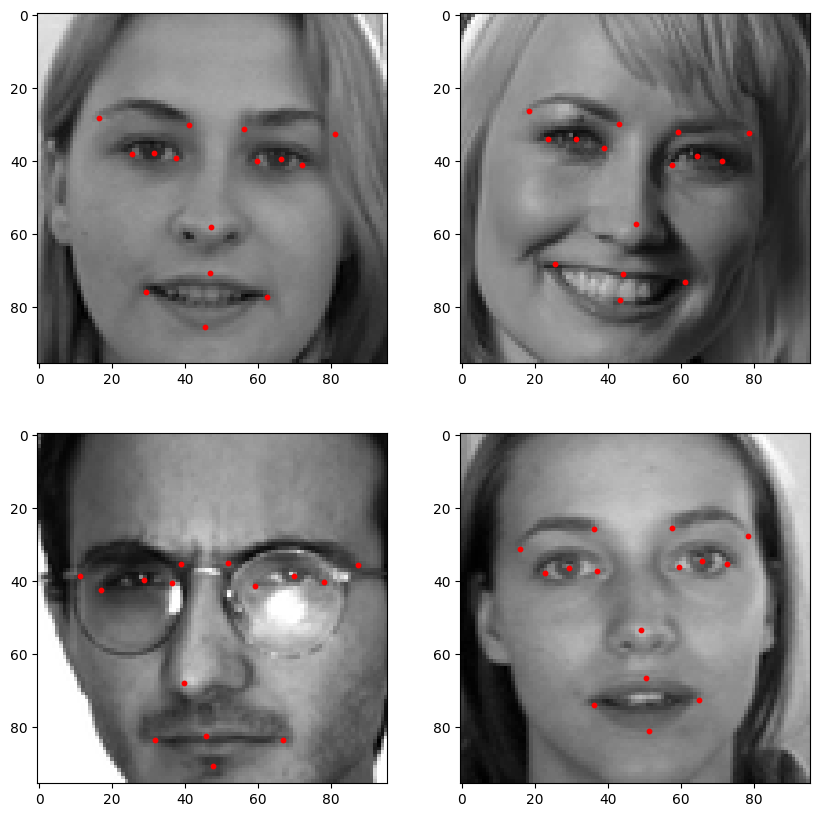

In [4]:
ff.plotFaces(X,y)

Kluczowe punkty na bliskich zdjęciach twarzy znajdują się zawsze mniej więcej w tych samych miejscach, więc aby model nie nauczył się tylko tego dodajemy do zbioru danych obrócone obrazki

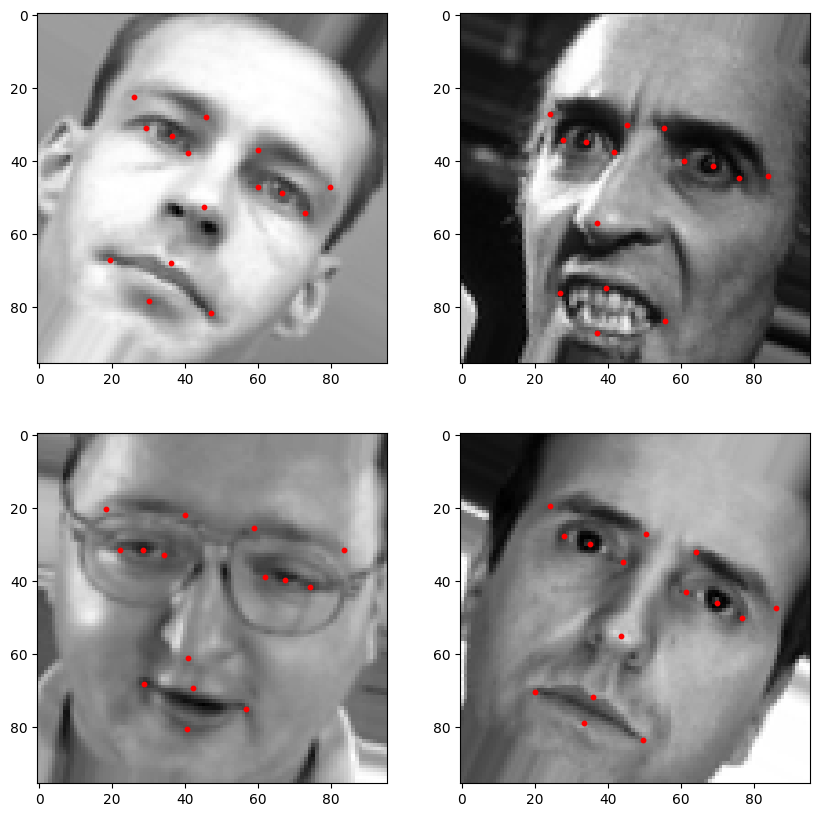

In [5]:
# augmentacja

X_rot = np.zeros(X.shape)
y_rot = np.zeros(y.shape)
# bardzo proszę wybaczyć mi pętlę....
for i in range(len(X)):
    X_rot[i], y_rot[i] = ff.rotate_image_and_keypoints(X[i],y[i])

ff.plotFaces(X_rot,y_rot)

X_ex = np.concatenate((X,X_rot), axis=0)
y_ex = np.concatenate((y,y_rot), axis=0)

Tworzymy datasety tensorflowa, które będą optymalne do treningu. Sprawdzamy też prędkość czytania danych.

In [6]:
# tworzenie datasetu optymalnego do trenowania modelu
dataset = tf.data.Dataset.from_tensor_slices((X_ex, y_ex)).shuffle(5000)
dataset_train = dataset.skip(200)
dataset_train = dataset_train.batch(64).prefetch(tf.data.AUTOTUNE)
dataset_val = dataset.take(200)
dataset_val = dataset_val.batch(64).prefetch(tf.data.AUTOTUNE)

In [ ]:
ff.reading_time(dataset_train)

Czas odczytu: 0.10s
Liczba odczytanych przykładów: 4080
Średnia prędkość odczytu: 42658.09 przykładów/s


Testujemy jednocześnie klika modeli aby móc je ze sobą porównywać i metodą prób i błędów zobaczyć co sprawdza się najlepiej. Przetestowałam wiele różnych, prostych i skomplikowanych modeli, wyniki pokazuję dla czterech wybranych, ale wnioski są oparte na wszystkich próbach.

In [7]:
# tworzenie 4 różnych modeli
model_1 = tf.keras.Sequential(name='CNN_1', layers=[
        tf.keras.layers.Input(shape=(96, 96, 1)),

        tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dense(30)
])

model_2 = tf.keras.Sequential(name='CNN_2', layers=[
        tf.keras.layers.Input(shape=(96, 96, 1)),

        tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
        tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
        tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
        tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dense(30)
])

model_3 = tf.keras.Sequential(name='CNN_3', layers=[
        tf.keras.layers.Input(shape=(96, 96, 1)),

        tf.keras.layers.Conv2D(32, (5, 5), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(30)
])

model_4 = tf.keras.Sequential(name='CNN_4', layers=[
        tf.keras.layers.Input(shape=(96, 96, 1)),

        tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2, 2),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(30)
])

models = [model_1, model_2, model_3, model_4]
labels = ['model 1', 'model 2', 'model 3', 'model 4']

Definiujemy dwie metryki, które będą bardzo przydatne w tym problemie. Pierwsza to średnia odległość prawdziwych punktów od przewidywanych punktów, druga mówi nam jaka część punktów jest w mniej odległa od prawdziwych punktów niż threshold = 3. Obie metryki są dużo bardziej intuicyjne niż standardowe i pomogą nam ocenić, jak radzą sobie modele.

In [9]:
def mean_distance_error(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true = tf.reshape(y_true, (-1, 15, 2))
    y_pred = tf.reshape(y_pred, (-1, 15, 2))
    distances = tf.norm(y_true - y_pred, axis=-1)
    return tf.reduce_mean(distances)*96

def percentage_below_threshold(y_true, y_pred, threshold=3):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), (-1, 15, 2))
    y_pred = tf.reshape(tf.cast(y_pred, tf.float32), (-1, 15, 2))
    distances = tf.norm(y_true - y_pred, axis=-1) * 96
    return tf.reduce_mean(tf.cast(distances < threshold, tf.float32))

mean_distance_error.__name__ = 'mde'
percentage_below_threshold.__name__ = 'pbt'

In [10]:
# trening
initial_learning_rate = 0.001
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(initial_learning_rate,
                decay_steps=500,
                decay_rate=0.95,
                staircase=False)

callback = tf.keras.callbacks.EarlyStopping(monitor='val_mde', mode='min', patience=10, min_delta=1e-3,
                                            restore_best_weights=True, verbose=1)

histories = []
for model in models:

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
                  loss='mse', metrics=[mean_distance_error, percentage_below_threshold])

    history = model.fit(dataset_train,
                    validation_data=dataset_val,
                    epochs=100,
                    callbacks=[callback],
                    verbose=0)
    histories.append(history)

    print(model.name, 'finished')
    best_epoch = np.argmin(history.history['val_mde'])
    print("Best Epoch:", best_epoch + 1)
    print("loss:", history.history['loss'][best_epoch])
    print("val_loss:", history.history['val_loss'][best_epoch])
    print("mde:", history.history['mde'][best_epoch])
    print("val_mde:", history.history['val_mde'][best_epoch])
    print("pbt:", history.history['pbt'][best_epoch])
    print("val_pbt:", history.history['val_pbt'][best_epoch])
    print('\n')


Restoring model weights from the end of the best epoch: 97.
CNN_1 finished
Best Epoch: 97
loss: 4.725429607788101e-05
val_loss: 3.8260022847680375e-05
mde: 0.7970142364501953
val_mde: 0.7279865145683289
pbt: 0.9978193640708923
val_pbt: 0.999218761920929


Epoch 93: early stopping
Restoring model weights from the end of the best epoch: 83.
CNN_2 finished
Best Epoch: 83
loss: 0.0001128584990510717
val_loss: 0.0001000587290036492
mde: 1.2120392322540283
val_mde: 1.088624119758606
pbt: 0.9717610478401184
val_pbt: 0.9807292222976685


Epoch 80: early stopping
Restoring model weights from the end of the best epoch: 70.
CNN_3 finished
Best Epoch: 70
loss: 5.6736516853561625e-05
val_loss: 4.593147605191916e-05
mde: 0.872622549533844
val_mde: 0.7704846262931824
pbt: 0.9956979751586914
val_pbt: 0.9955729842185974


Epoch 58: early stopping
Restoring model weights from the end of the best epoch: 48.
CNN_4 finished
Best Epoch: 48
loss: 0.0009494739933870733
val_loss: 0.00033199955942109227
mde: 3.

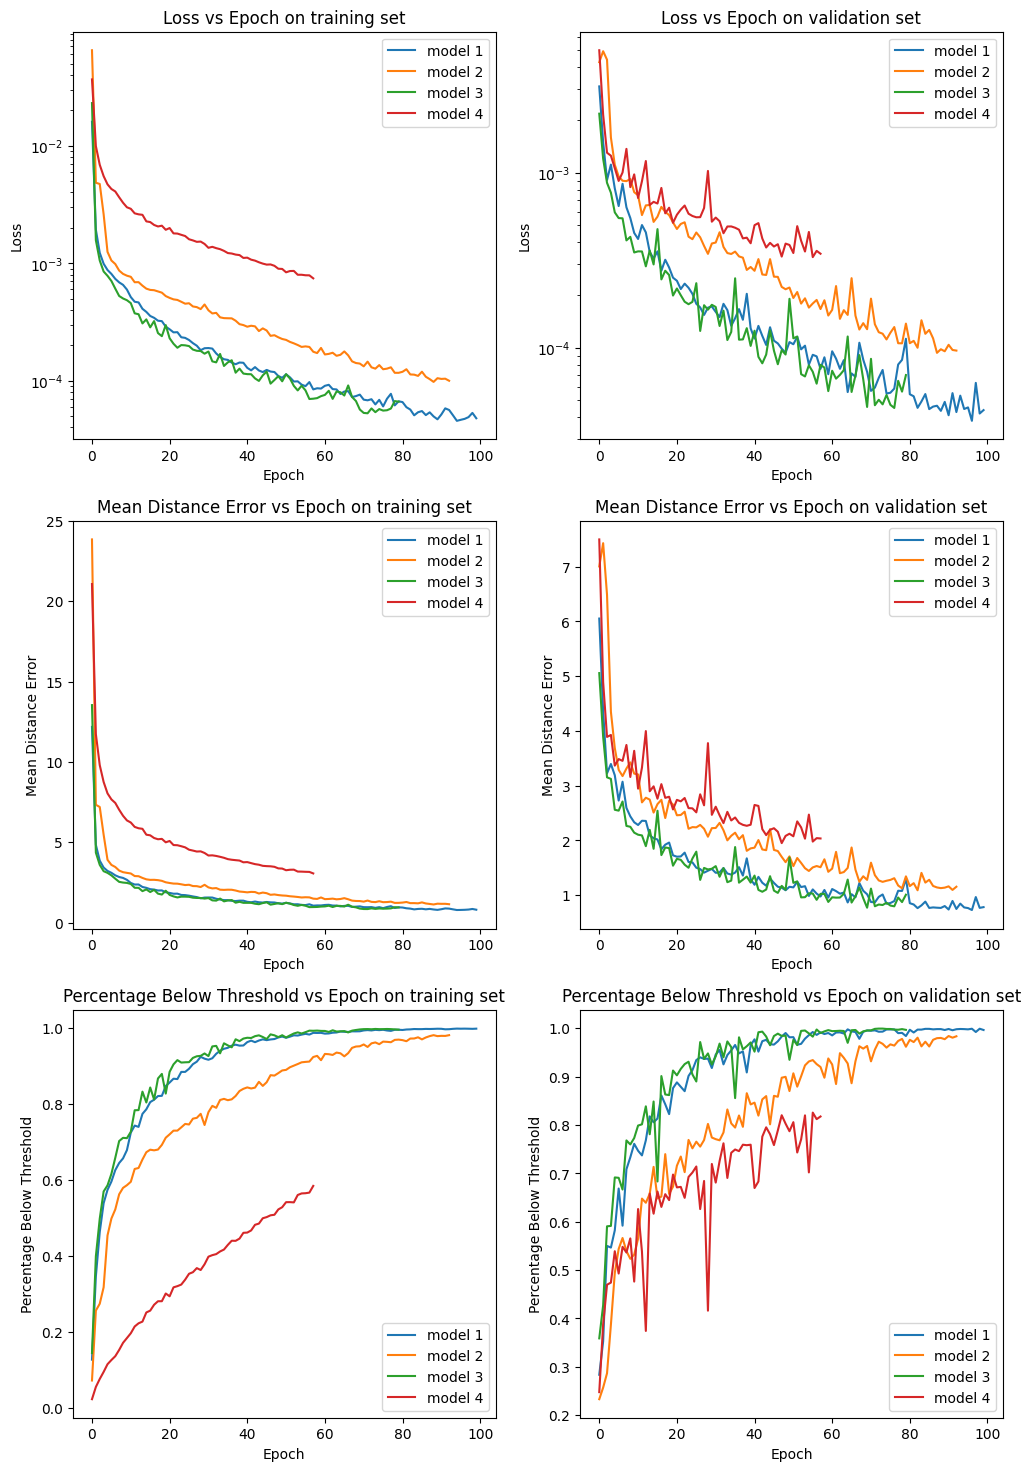

In [11]:
fig, axes = plt.subplots(3,2, figsize=(12,18))

for i in range(len(models)):

    history = histories[i]
    label = labels[i]

    axes[0,0].plot(history.history['loss'], label=label)
    axes[0,0].set_xlabel('Epoch')
    axes[0,0].set_ylabel('Loss')
    axes[0,0].legend()
    axes[0,0].set_yscale('log')
    axes[0,0].set_title('Loss vs Epoch on training set')
    axes[0,1].plot(history.history['val_loss'], label=label)
    axes[0,1].set_xlabel('Epoch')
    axes[0,1].set_ylabel('Loss')
    axes[0,1].legend()
    axes[0,1].set_yscale('log')
    axes[0,1].set_title('Loss vs Epoch on validation set')

    axes[1,0].plot(history.history['mde'], label=label)
    axes[1,0].set_xlabel('Epoch')
    axes[1,0].set_ylabel('Mean Distance Error')
    axes[1,0].legend()
    axes[1,0].set_title('Mean Distance Error vs Epoch on training set')
    axes[1,1].plot(history.history['val_mde'], label=label)
    axes[1,1].set_xlabel('Epoch')
    axes[1,1].set_ylabel('Mean Distance Error')
    axes[1,1].legend()
    axes[1,1].set_title('Mean Distance Error vs Epoch on validation set')

    axes[2,0].plot(history.history['pbt'], label=label)
    axes[2,0].set_xlabel('Epoch')
    axes[2,0].set_ylabel('Percentage Below Threshold')
    axes[2,0].legend()
    axes[2,0].set_title('Percentage Below Threshold vs Epoch on training set')
    axes[2,1].plot(history.history['val_pbt'], label=label)
    axes[2,1].set_xlabel('Epoch')
    axes[2,1].set_ylabel('Percentage Below Threshold')
    axes[2,1].legend()
    axes[2,1].set_title('Percentage Below Threshold vs Epoch on validation set')


plt.show()

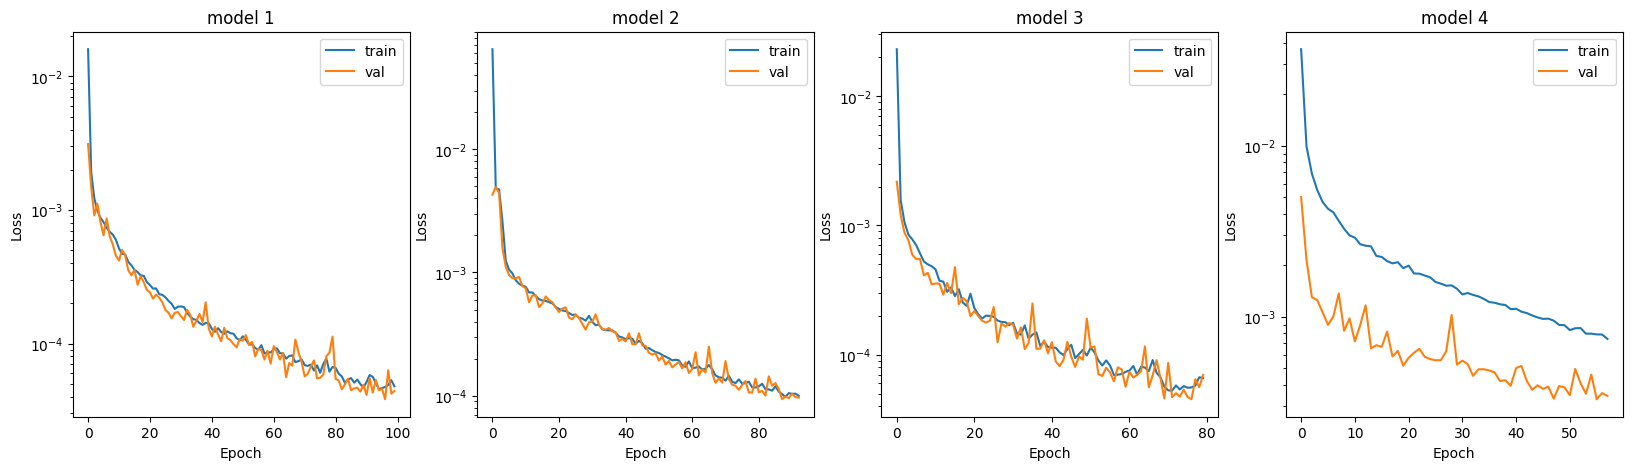

In [12]:
# porównanie loss i val_loss
fig, axes = plt.subplots(1,4, figsize=(20,5))

for i in range(len(models)):

    history = histories[i]
    label = labels[i]

    axes[i].plot(history.history['loss'], label='train')
    axes[i].plot(history.history['val_loss'], label='val')
    axes[i].set_xlabel('Epoch')
    axes[i].set_ylabel('Loss')
    axes[i].legend()
    axes[i].set_yscale('log')
    axes[i].set_title(label)



Jak widać modele 1, 2 i 3 radzą sobie tutaj bardzo dobrze. Wydaje się, że zbytnia komplikacja modelu i dodawanie warstw (jak np w modelu 2) nic nie daje - nie ma sensu robić modelu głębszego niż model 1. Okazuje się nawet, że zdredukowanie modelu jeszcze bardziej (jak np w modelu 3) również przynosi zadowalające efekty. Sensowne jest również użycie nieco większego filtra w pierwszej warstwie (jak w modelu 3)

Dodanie dropoutu (ale również regularyzacji, batch normalization i innych takich) skutkuje dużo gorszymi efektami tereningu (patrząc na metryki). Co więcej na prównaniu loss i val_loss, nie wydaje się by modele się przeuczały, więc nie wydaje się to potrzebne.

y_true - punkty czerwone, y_pred - punkty niebieskie
JEDEN Z MODELI BEZ DROPOUTU


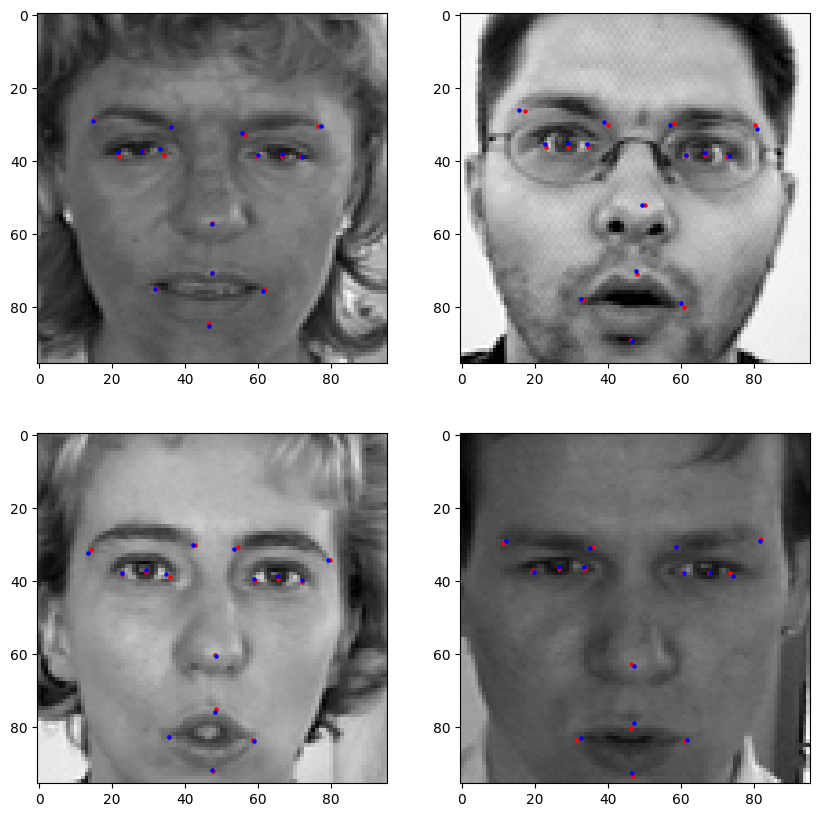

MODEL Z DROPOUTEM


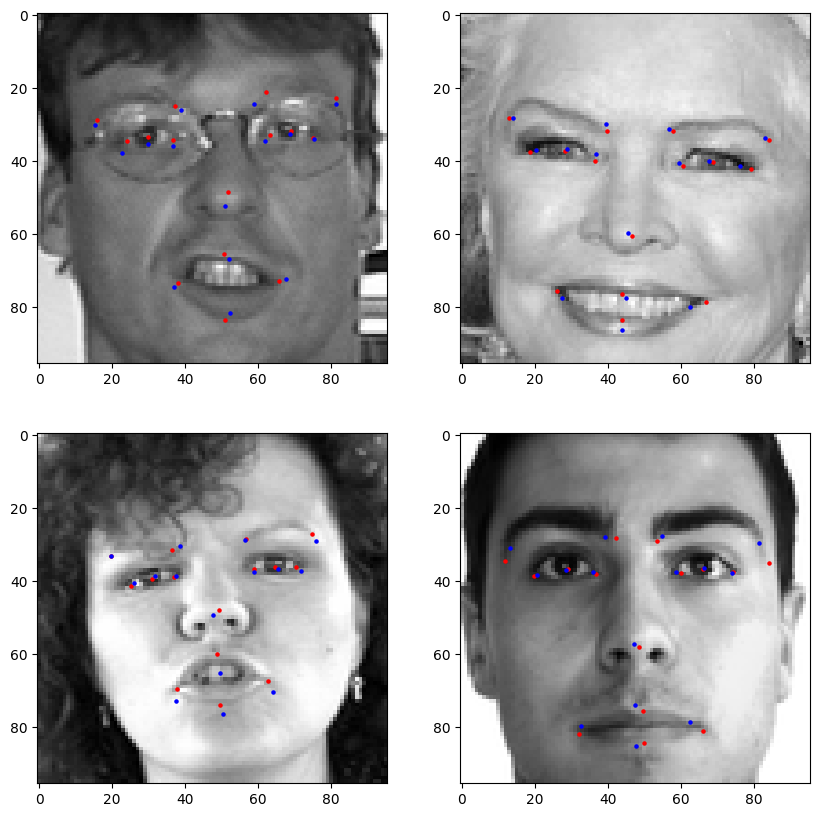

In [13]:
print('y_true - punkty czerwone, y_pred - punkty niebieskie')
print('JEDEN Z MODELI BEZ DROPOUTU')
y_pred = models[0].predict(X, verbose=0)
ff.plotFaces(X, y, y_pred, s=5)

print('MODEL Z DROPOUTEM')
y_pred = models[3].predict(X, verbose=0)
ff.plotFaces(X, y, y_pred, s=5)

In [14]:
# załadowanie danych testowych
df_test = pd.read_csv('test.csv')
X_test = ff.load_test_images(df_test.dropna())

Teraz możemy skorzystać z danych testowych, które zawierają same obrazki bez zaznaczonych kluczowych punktów. Możemy jednak "na oko" ocenić, jak radzą sobie modele.

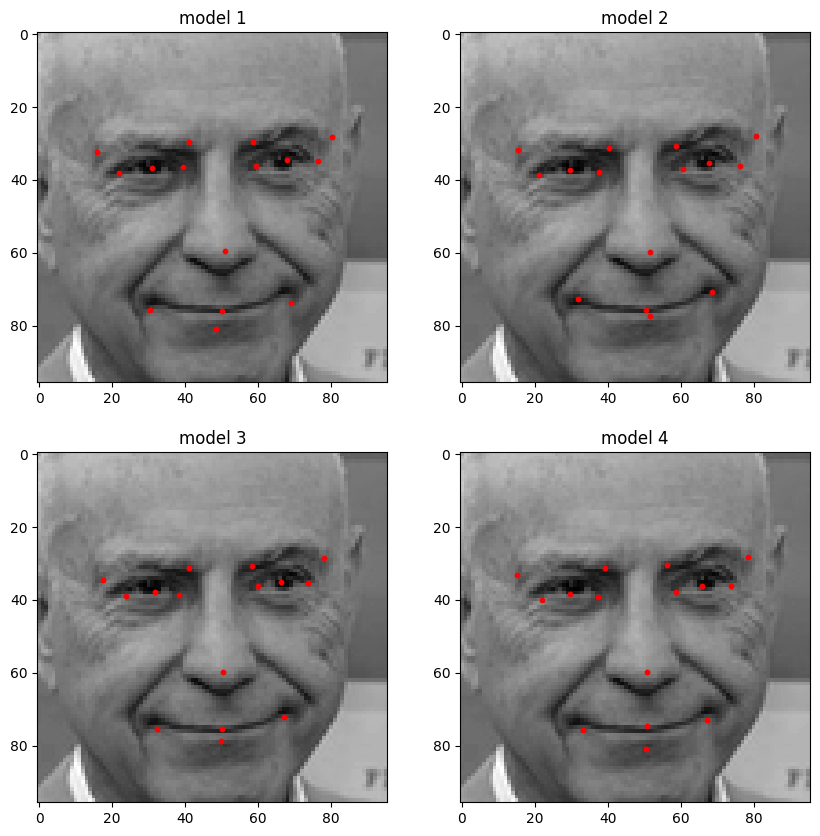

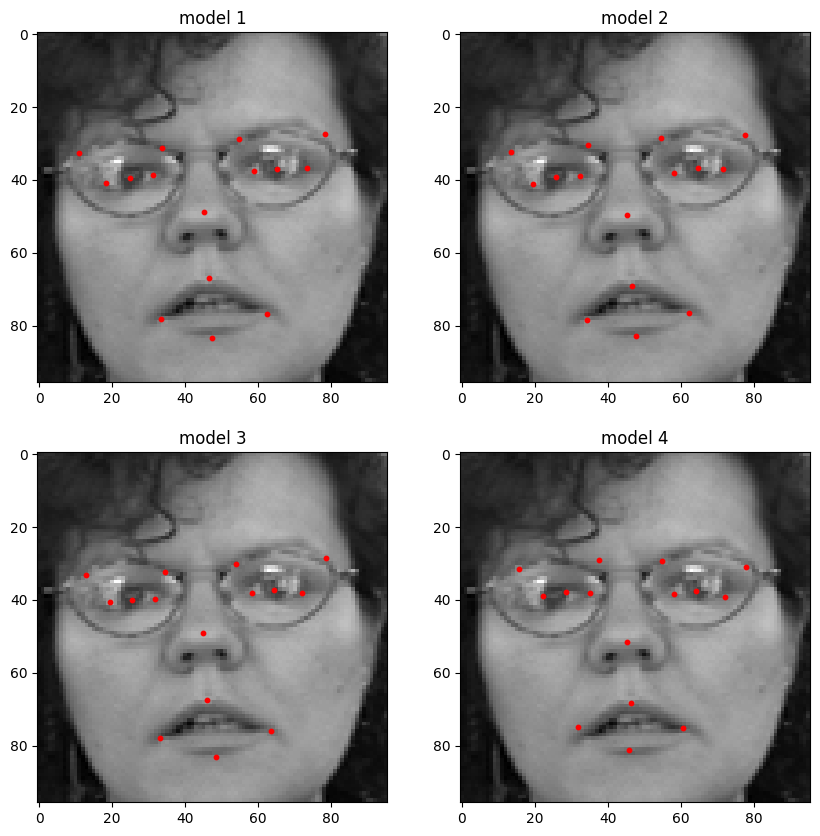

In [15]:
# porównanie jak modele radzą sobie na testowych twarzach
ff.compare_models(X_test, models, labels)
ff.compare_models(X_test, models, labels)

Jak widać modele radzą sobie całkiem nieźle, duże problemy mają jedynie z obrazkami gdzie słabo widać twarz albo część jest zakryta. Przy mniej oczywistych obrazkach często najlepiej radzi sobie model z dropoutem (który na zbiorze treningowym i walidacyjnym osiąga słabsze wyniki od pozostałych modeli), czyli możliwe, że jednak to on najlepiej by się generalizował.

Spróbowałam jeszcze stworzyć pare innych modeli. Zacznijmy od modelu, który ma usuwać szum z obrazków.

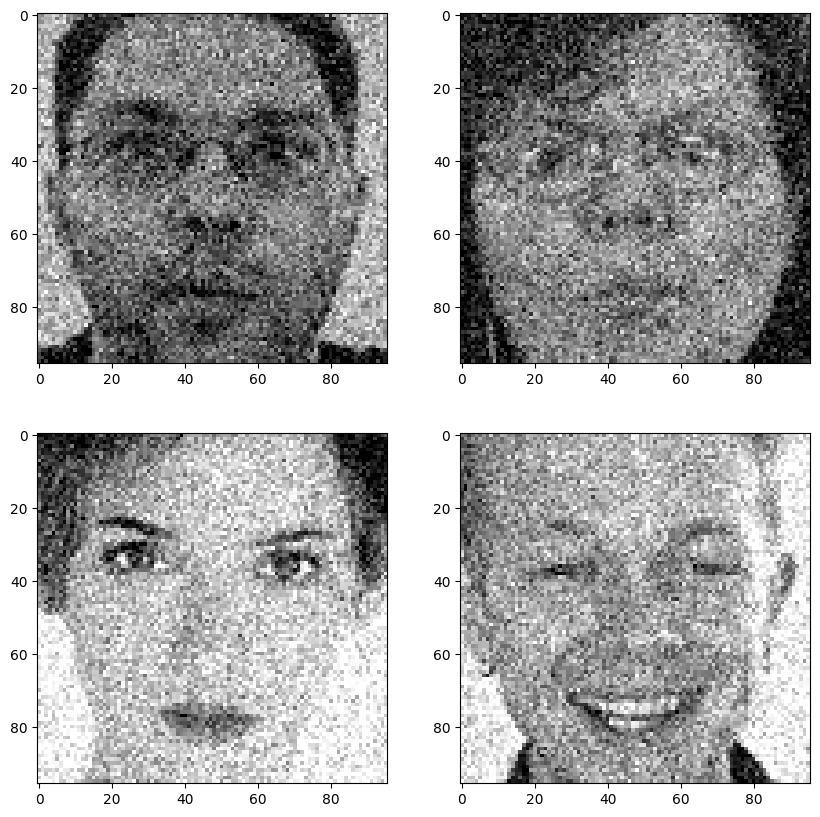

In [ ]:
# dodawanie szumu do obrazków
def add_noise(images, noise_factor=0.13):
    noisy = images + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=images.shape)
    return np.clip(noisy, 0., 1.)

X_noise = add_noise(X)

ff.plotFaces(X_noise)

In [ ]:
# tworzenie optymalnych datasetów
dataset_noise = tf.data.Dataset.from_tensor_slices((X_noise,X)).shuffle(4000)
dataset_noise_t = dataset_noise.skip(500).batch(64)
dataset_noise_v = dataset_noise.take(500).batch(64)

In [ ]:
# tworzenie modelu
encoder = tf.keras.Sequential([
              tf.keras.Input(shape=(96, 96, 1)),
              tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same', strides=2),
              tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same', strides=2),
              tf.keras.layers.Conv2D(128, 3, activation='relu', padding='same', strides=2),
              tf.keras.layers.Conv2D(256, 3, activation='relu', padding='same', strides=1),
          ])

decoder = tf.keras.Sequential([
              tf.keras.Input(shape=(12, 12, 256)),
              tf.keras.layers.Conv2DTranspose(128, 3, activation='relu', padding='same', strides=2),
              tf.keras.layers.Conv2DTranspose(64, 3, activation='relu', padding='same', strides=2),
              tf.keras.layers.Conv2DTranspose(32, 3, activation='relu', padding='same', strides=2),
              tf.keras.layers.Conv2DTranspose(1, 3, activation='sigmoid', padding='same', strides=1),
          ])


model_denoising = tf.keras.Sequential([encoder, decoder])

In [ ]:
# trening
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(initial_learning_rate=0.001, decay_steps=500, decay_rate=0.9, staircase=False)

model_denoising.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule), loss='mse')

callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss',
                                          patience=5,
                                          restore_best_weights=True,
                                          verbose=1)

history = model_denoising.fit(dataset_noise_t,
                              validation_data= dataset_noise_v,
                              epochs=50,
                              verbose=1,
                              callbacks=[callback])

Epoch 1/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 13s 269ms/step - loss: 0.0515 - val_loss: 0.0278
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0199 - val_loss: 0.0107
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0097 - val_loss: 0.0071
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0067 - val_loss: 0.0054
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0055 - val_loss: 0.0047
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0045 - val_loss: 0.0043
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0044 - val_loss: 0.0039
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0038 - val_loss: 0.0036
Epoch 9/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0037 - val_loss: 0.0046
Epoch 10/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0040 - val_loss: 0.0034
Epoch 11/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0034 - val_loss: 0.0034
Epoch 12/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0

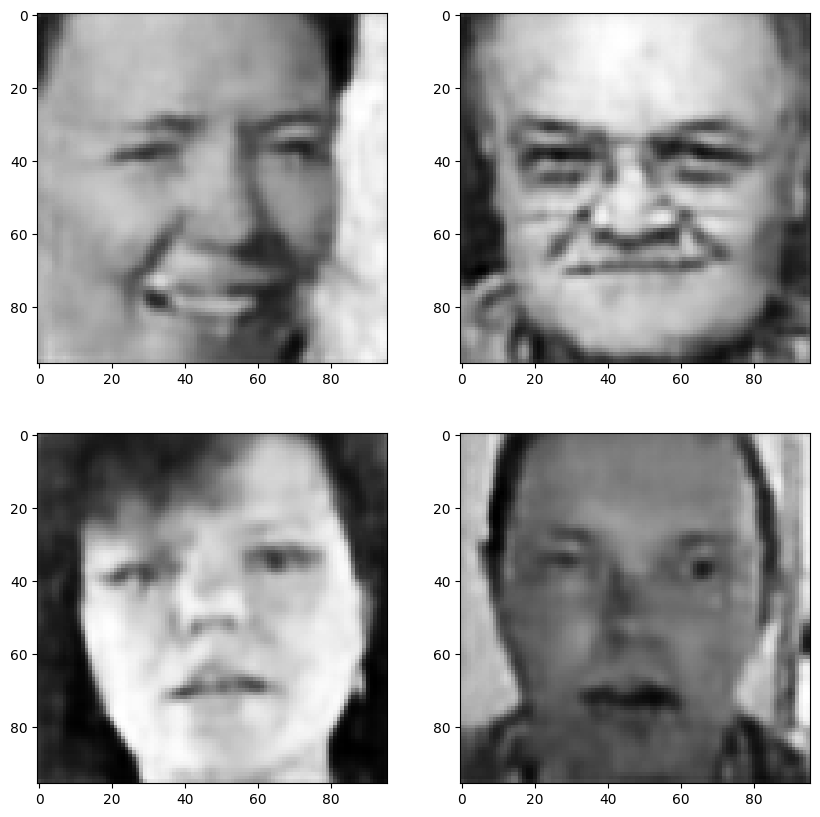

In [ ]:
X_test_noise = add_noise(X_test)
X_pred = model_denoising.predict(X_test_noise, verbose=0)
ff.plotFaces(X_pred)

Obraki wyjściowe są nieco rozmazane i zniekształcone, ale szum został usunięty i bez problemu można rozpoznać przedstawiane twarze

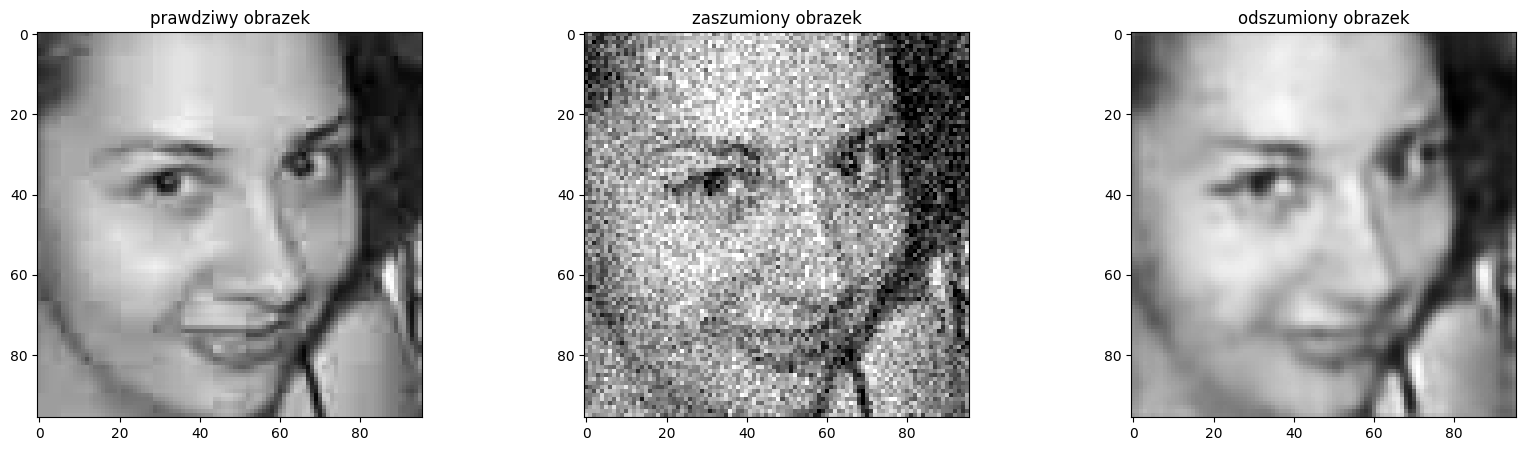

In [ ]:
index = np.random.default_rng().integers(0, X_test.shape[0], (1))
face = X_test[index]
face_noise = X_test_noise[index]
face_denoise = X_pred[index]

fig, axes = plt.subplots(1,3, figsize=(20,5))
axes[0].imshow(face.reshape(96,96), cmap='gray')
axes[0].set_title('prawdziwy obrazek')
axes[1].imshow(face_noise.reshape(96,96), cmap='gray')
axes[1].set_title('zaszumiony obrazek')
axes[2].imshow(face_denoise.reshape(96,96), cmap='gray')
axes[2].set_title('odszumiony obrazek')
plt.show()

Stworzyłam jeszcze autoenkoder, który kompresuje obrazki 96x96 do przestrzeni 96-wymiarowej oraz je rekonstruuje.

In [ ]:
# przygotowanie datasetów
all_faces = np.concatenate((X,X_test), axis=0)
dataset_faces = tf.data.Dataset.from_tensor_slices((all_faces,all_faces)).shuffle(4000)
train_faces = dataset_faces.skip(500).batch(64)
val_faces = dataset_faces.take(500).batch(64)

In [ ]:
# tworzenie autoenkodera
encoder = tf.keras.Sequential(layers=[tf.keras.Input(shape=(96,96,1)),
                              tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation=tf.keras.activations.leaky_relu, padding='same', strides=2),
                              tf.keras.layers.Conv2D(filters=64, kernel_size=3, activation=tf.keras.activations.leaky_relu, padding='same', strides=2),
                              tf.keras.layers.Conv2D(filters=128, kernel_size=3, activation=tf.keras.activations.leaky_relu, padding='same', strides=2),
                              tf.keras.layers.Flatten(),
                              tf.keras.layers.Dense(96, activation=tf.keras.activations.leaky_relu)])

decoder = tf.keras.Sequential(layers=[tf.keras.Input(shape=(96,)),
                                      tf.keras.layers.Dense(12*12*128, activation=tf.keras.activations.leaky_relu),
                                      tf.keras.layers.Reshape((12,12,128)),
                                      tf.keras.layers.Conv2DTranspose(filters=128, kernel_size=3, activation=tf.keras.activations.leaky_relu, padding='same', strides=2),
                                      tf.keras.layers.Conv2DTranspose(filters=64, kernel_size=3, activation=tf.keras.activations.leaky_relu, padding='same', strides=2),
                                      tf.keras.layers.Conv2DTranspose(filters=32, kernel_size=3, activation=tf.keras.activations.leaky_relu, padding='same', strides=2),
                                      tf.keras.layers.Conv2DTranspose(filters=1, kernel_size=3, activation='sigmoid', padding='same', strides=1)])

model = tf.keras.Sequential([encoder, decoder])

In [ ]:
# trening
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(initial_learning_rate=0.001, decay_steps=200, decay_rate=0.95, staircase=True)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule), loss='mse')

callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss',
                                          patience=3,
                                          min_delta=1E-4,
                                          restore_best_weights=True,
                                          verbose=1)

history = model.fit(train_faces,
                    validation_data=val_faces,
                    epochs=50,
                    verbose=1,
                    callbacks=[callback])

Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - loss: 0.0536 - val_loss: 0.0352
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 0.0273 - val_loss: 0.0175
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0156 - val_loss: 0.0122
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0119 - val_loss: 0.0105
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0100 - val_loss: 0.0091
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0089 - val_loss: 0.0081
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0080 - val_loss: 0.0073
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0074 - val_loss: 0.0068
Epoch 9/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0067 - val_loss: 0.0062
Epoch 10/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0065 - val_loss: 0.0064
Epoch 11/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0060 - val_loss: 0.0058
Epoch 12/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0

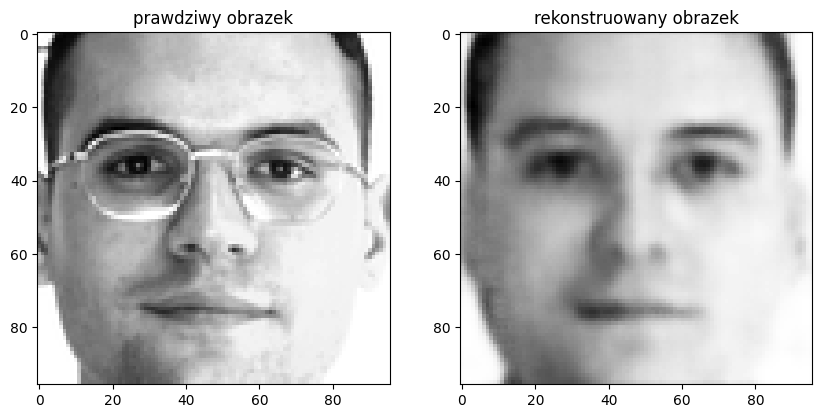

reprezentacja obrazka w latent space: 
 [ 1.5722245   2.7449787   6.4544864   2.9454598   2.7511044   1.8657238
  2.2421632   1.474084    5.0165205   2.0904098   4.082894    2.8652704
  0.40148914  5.3581314   2.051774   -2.238636    3.0410757   1.7720442
  4.5712037   4.0612235   1.1751482   1.5132035   1.407532    3.8288126
  2.162184   -0.33196205  3.9005659   1.8689451   1.9414399   1.0291915
  1.0879668   2.4405665   2.2179453   2.2116308   7.1578608   3.852966
  1.0706296   3.1961503   5.016503    1.4267788   4.4483366   0.01303074
  3.6407368   2.5428684   3.2356763   7.841187    6.387384    1.270227
  2.1745026   1.3241495   5.271257    4.9658847   2.779247    7.9297023
  1.3817962   0.98720413  2.6427467   1.5286821   1.9652951   2.7214437
  1.3265185   2.2574155   5.1899014   3.6425624   1.9106624   1.1489997
  2.5900948   3.2255807   3.7556252   1.4776635   2.780821    3.833783
  5.530209    1.1861022   1.7024802   4.0899916   7.965149    1.2299066
  5.162977    1.3523147   

In [ ]:
index = np.random.default_rng().integers(0, all_faces.shape[0], (1))
face = all_faces[index]
reconstructed_face = model.predict(face, verbose=0)

fig, axes = plt.subplots(1,2, figsize=(10,10))
axes[0].imshow(face.reshape(96,96), cmap='gray')
axes[0].set_title('prawdziwy obrazek')
axes[1].imshow(reconstructed_face.reshape(96,96), cmap='gray')
axes[1].set_title('rekonstruowany obrazek')
plt.show()

z = model.layers[0].predict(face, verbose=0)
print('reprezentacja obrazka w latent space: \n', z[0])

Jak widać autoenkoder zachowuje ogólną strukturę twarzy, ale pomija mniej znaczące elementy, jak np okulary.

Na koniec spróbowałam stworzyć autoenkoder wariacyjny, dzięki któremu będzie można generować nowe twarze.

In [ ]:
latent_dim = 96

class Sampling(tf.keras.layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# ENCODER
encoder_inputs = tf.keras.layers.Input(shape=(96, 96, 1))
x = tf.keras.layers.Conv2D(32, 3, activation='relu', strides=2, padding='same')(encoder_inputs)
x = tf.keras.layers.Conv2D(64, 3, activation='relu', strides=2, padding='same')(x)
x = tf.keras.layers.Conv2D(128, 3, activation='relu', strides=2, padding='same')(x)
x = tf.keras.layers.Flatten()(x)
x = tf.keras.layers.Dense(256, activation='relu')(x)

z_mean = tf.keras.layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = tf.keras.layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

encoder = tf.keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")

# DECODER
latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))
x = tf.keras.layers.Dense(12 * 12 * 128, activation="relu")(latent_inputs)
x = tf.keras.layers.Reshape((12, 12, 128))(x)
x = tf.keras.layers.Conv2DTranspose(128, 3, activation="relu", strides=2, padding="same")(x)
x = tf.keras.layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
x = tf.keras.layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)
decoder_outputs = tf.keras.layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")(x)

decoder = tf.keras.Model(latent_inputs, decoder_outputs, name="decoder")

In [ ]:
class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2),
                )
            )
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            total_loss = reconstruction_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def call(self, inputs):
        _, _, z = self.encoder(inputs)
        return self.decoder(z)


# tworzenie modelu
vae = VAE(encoder, decoder)

In [ ]:
dataset_faces = tf.data.Dataset.from_tensor_slices(all_faces).shuffle(4000).batch(64)

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(initial_learning_rate=0.001, decay_steps=1000, decay_rate=0.9, staircase=True)

callback = tf.keras.callbacks.EarlyStopping(monitor='loss',
                                          patience=10,
                                          restore_best_weights=True,
                                          verbose=1)

vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule))

history = vae.fit(dataset_faces, epochs=200, callbacks=[callback], verbose=1)


Epoch 1/200
62/62 ━━━━━━━━━━━━━━━━━━━━ 12s 78ms/step - kl_loss: 3.6675 - loss: 6334.4233 - reconstruction_loss: 6330.7559
Epoch 2/200
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - kl_loss: 25.6716 - loss: 6036.4546 - reconstruction_loss: 6010.7842
Epoch 3/200
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - kl_loss: 40.6011 - loss: 5768.7368 - reconstruction_loss: 5728.1353
Epoch 4/200
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - kl_loss: 48.3199 - loss: 5662.6333 - reconstruction_loss: 5614.3135
Epoch 5/200
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - kl_loss: 51.6665 - loss: 5628.0244 - reconstruction_loss: 5576.3574
Epoch 6/200
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - kl_loss: 53.8500 - loss: 5597.3931 - reconstruction_loss: 5543.5430
Epoch 7/200
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - kl_loss: 54.1947 - loss: 5586.4956 - reconstruction_loss: 5532.3008
Epoch 8/200
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - kl_loss: 55.0012 - loss: 5580.8989 - reconstruction_loss: 5525.8979
Epoch 9/200
62/62 ━━━━━━

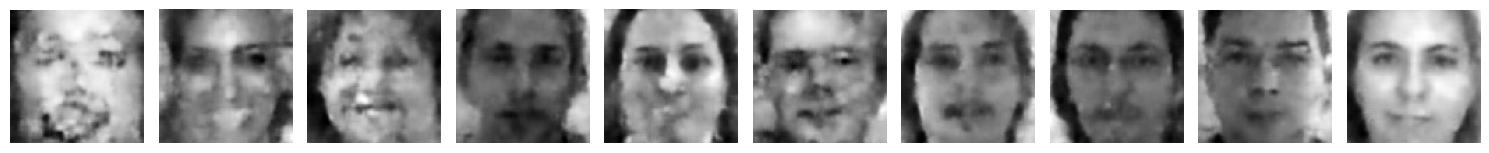

In [ ]:
def generate_faces(vae, num_images=10):
    latent_dim = 96
    z_samples = np.random.normal(size=(num_images, latent_dim))
    generated = vae.decoder.predict(z_samples, verbose=0)


    plt.figure(figsize=(15, 3))
    for i in range(num_images):
        plt.subplot(1, num_images, i + 1)
        plt.imshow(generated[i].squeeze(), cmap='gray')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

generate_faces(vae, num_images=10)

Udało się wygenerować nowe obrazki i na niektórych rzeczywiście widzimy całkiem sensowne twarze.

PODSUMOWANIE

W ramach pracy ze zbiorem obrazków twarzy udało się zaprojektować i przetestować kilka interesujących modeli:

1. Lokalizowanie kluczowych punktów twarzy

Zaprojektowano i porównano wiele modeli lokalizowania punktów charakterystycznych twarzy. Okazało się, że najlepiej sprawdzają się płytsze architektury CNN, a dodanie dropoutu wydaje się poprawiać zdolność modelu do generalizacji. Pomimo tego, że część punktów w zbiorze treningowym była oznaczona niedokładnie, modele osiągały zadowalające rezultaty i były w stanie wiarygodnie lokalizować kluczowe elementy twarzy (oczy, nos, usta).

2. Odszumianie obrazków twarzy

Zbudowany autoenkoder z powodzeniem usuwał szum z obrazków. Choć rezultaty bywały lekko rozmyte, należy zaznaczyć, że także oryginalne dane wejściowe były dość niewyraźne. Oczyszczone obrazy zachowywały ogólne cechy twarzy, co wskazuje na to, że model nauczył się skutecznie odfiltrowywać zakłócenia.

3. Autoencoder

Zbudowany autoenkoder pozwolił na zakodowanie obrazu do 96-wymiarowej reprezentacji latentnej, a następnie na jego rekonstrukcję. W rekonstrukcjach widać było, że model pomijał mniej istotne detale (np. tło czy okulary), co pokazuje, jakie cechy obrazu uznaje za najważniejsze. Ciekawym efektem była czasem zmiana wyrazu twarzy (np. otwarte oczy zamiast przymkniętych). Mimo uproszczeń, twarze pozostawały rozpoznawalne, co sugeruje, że model nauczył się efektywnej reprezentacji twarzy.

4. Wariacyjny autoencoder

VAE również mapował obrazy do 96-wymiarowego przestrzeni latentnej, ale dodatkowo narzucał strukturę probabilistyczną, co umożliwiło generowanie nowych, nieistniejących twarzy. Wygenerowane obrazy były często nieco zniekształcone lub niewyraźne (a czasem wręcz przerażające), ale w wielu przypadkach przypominały realistyczne ludzkie twarze. To potwierdza, że model nauczył się uogólnionej reprezentacji twarzy.

W przyszłości warto zbadać, które wymiary przestrzeni latentnej odpowiadają za konkretne cechy twarzy – jak np. uśmiech, okulary czy kształt twarzy – i spróbować je manipulować, by kontrolować cechy generowanych twarzy.
